In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Model saving
import joblib

# Visualization settings
sns.set_theme(style="whitegrid")

# Display settings
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Load dataset
df_raw = pd.read_csv("C:/Users/HP/OneDrive/Desktop/data set/loan_approval_dataset (1).csv")

# Create a working copy
df = df_raw.copy()

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
# Data Cleaning
# Remove unnecessary spaces from column names
df.columns = df.columns.str.strip()

# Remove unnecessary spaces from categorical values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Column names and text values cleaned successfully!")
# Check duplicates before removal
print("Duplicates before cleaning:", df.duplicated().sum())

# Remove duplicate records
df.drop_duplicates(inplace=True)

print("Duplicates after cleaning:", df.duplicated().sum())
# Remove loan_id
df.drop("loan_id", axis=1, inplace=True)

print("Unnecessary columns removed!")

# Convert Education
df["education"] = df["education"].map({
    "Graduate": 1,
    "Not Graduate": 0
})

# Convert Self Employment
df["self_employed"] = df["self_employed"].map({
    "Yes": 1,
    "No": 0
})

# Convert Loan Status
df["loan_status"] = df["loan_status"].map({
    "Approved": 1,
    "Rejected": 0
})

print("Categorical variables converted successfully!")

print("First 5 records after preprocessing:")
display(df.head())

print("\nUpdated Data Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFinal Dataset Shape:", df.shape)

Column names and text values cleaned successfully!
Duplicates before cleaning: 0
Duplicates after cleaning: 0
Unnecessary columns removed!
Categorical variables converted successfully!
First 5 records after preprocessing:


,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,3,1,1,1187755,6301035,120,668,2221809,1103602,2740432,215697,1
1,1,1,0,544660,2169395,240,812,1698301,263034,767363,367284,1
2,4,0,0,1074591,383155,240,838,1915178,267675,304642,881846,1
3,3,0,1,652637,306667,240,561,1863381,234763,101745,418078,1
4,0,1,1,1002011,3912899,300,668,162898,750643,1348859,348754,1



Updated Data Types:
no_of_dependents            int64
education                   int64
self_employed               int64
income_annum                int64
loan_amount                 int64
loan_term                   int64
cibil_score                 int64
residential_assets_value    int64
commercial_assets_value     int64
luxury_assets_value         int64
bank_asset_value            int64
loan_status                 int64
dtype: object

Missing Values:
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

Final Dataset Shape: (2500, 12)


loan_status
1    1657
0     843
Name: count, dtype: int64


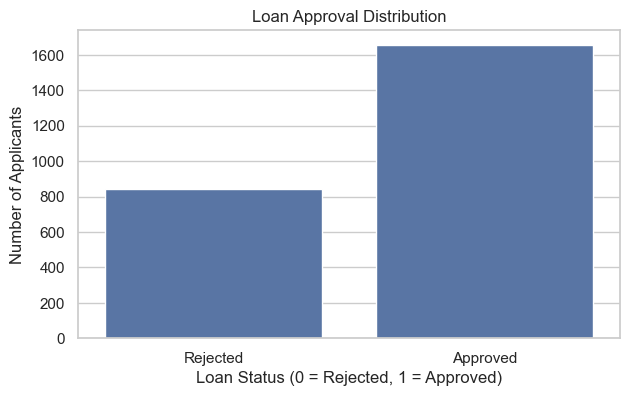

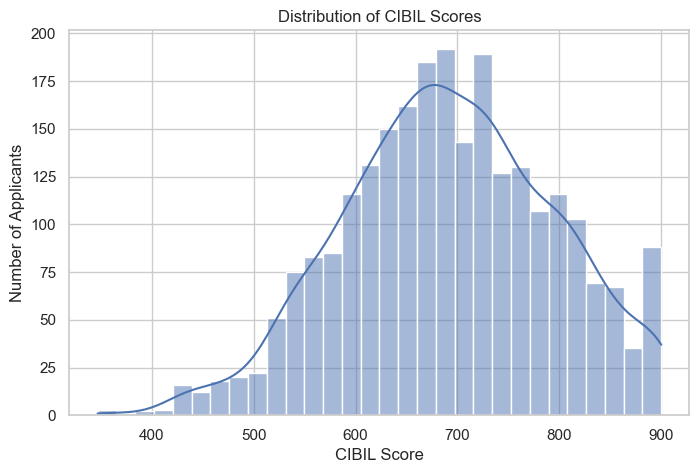

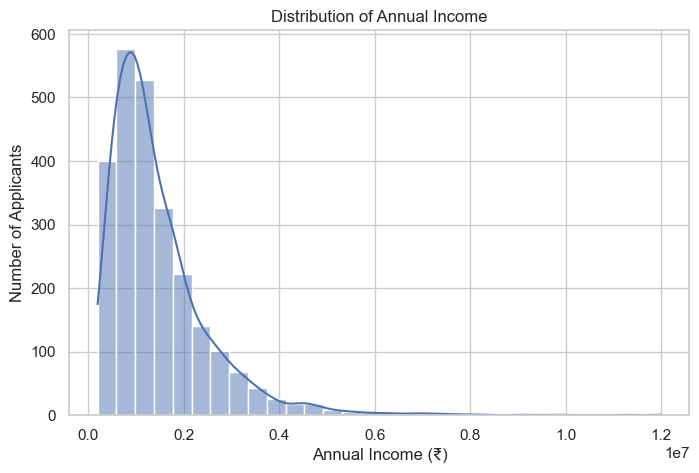

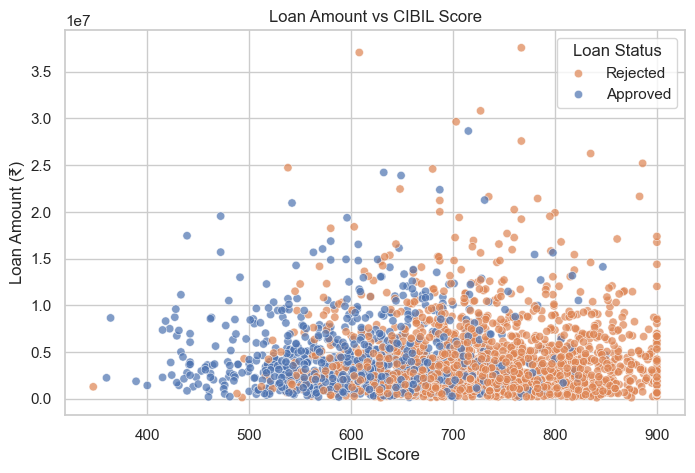

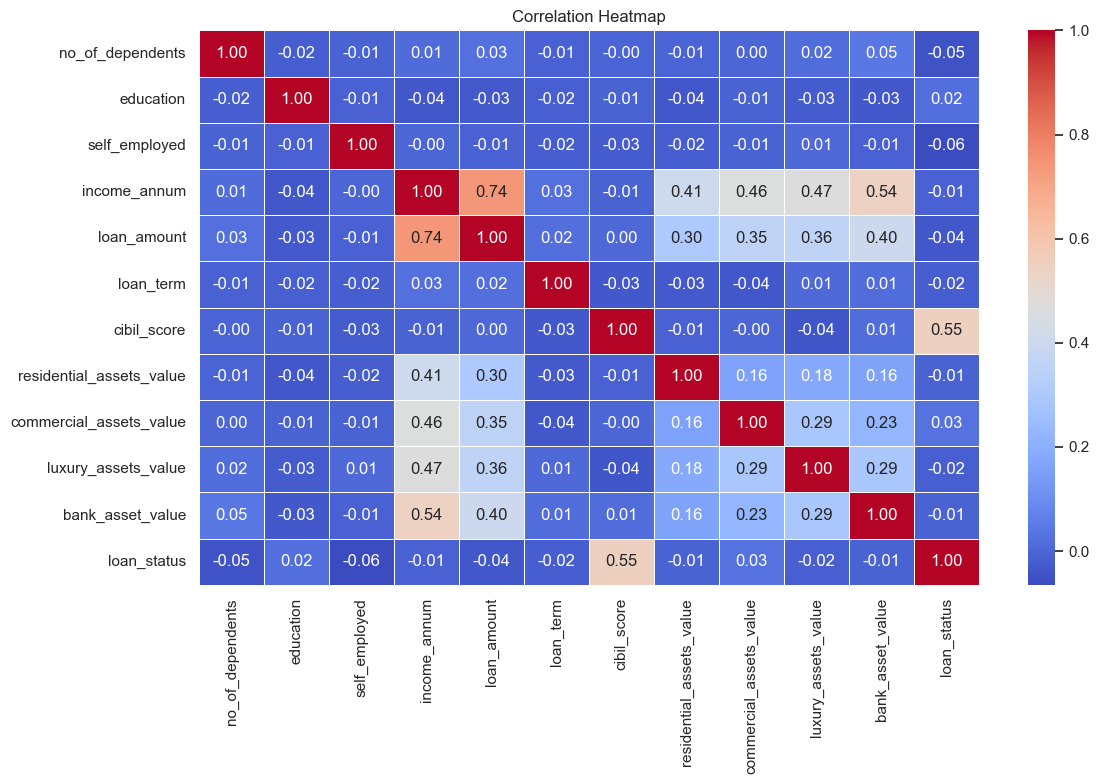

In [5]:
# Generate statistical summary
df.describe()

# Count loan approvals and rejections
print(df["loan_status"].value_counts())

# Visualize loan status
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="loan_status"
)

plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status (0 = Rejected, 1 = Approved)")
plt.ylabel("Number of Applicants")
plt.xticks([0, 1], ["Rejected", "Approved"])

plt.show()


#Credit score distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="cibil_score",
    bins=30,
    kde=True
)

plt.title("Distribution of CIBIL Scores")
plt.xlabel("CIBIL Score")
plt.ylabel("Number of Applicants")

plt.show()


#Income distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="income_annum",
    bins=30,
    kde=True
)

plt.title("Distribution of Annual Income")
plt.xlabel("Annual Income (₹)")
plt.ylabel("Number of Applicants")

plt.show()

#Loan amount vs CIBIL score
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="cibil_score",
    y="loan_amount",
    hue="loan_status",
    alpha=0.7
)

plt.title("Loan Amount vs CIBIL Score")
plt.xlabel("CIBIL Score")
plt.ylabel("Loan Amount (₹)")

plt.legend(
    title="Loan Status",
    labels=["Rejected", "Approved"]
)

plt.show()

# Correlation heatmap
plt.figure(figsize=(12, 8))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

In [6]:
# Feature Selection and Train-Test Split

# Separate independent variables
X = df.drop("loan_status", axis=1)

# Separate dependent variable
y = df["loan_status"]

print("Independent Variables (X):")
print(X.head())

print("\nDependent Variable (y):")
print(y.head())

#spliting 
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset splitting completed!")

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Independent Variables (X):
   no_of_dependents  education  self_employed  income_annum  loan_amount  \
0                 3          1              1       1187755      6301035   
1                 1          1              0        544660      2169395   
2                 4          0              0       1074591       383155   
3                 3          0              1        652637       306667   
4                 0          1              1       1002011      3912899   

   loan_term  cibil_score  residential_assets_value  commercial_assets_value  \
0        120          668                   2221809                  1103602   
1        240          812                   1698301                   263034   
2        240          838                   1915178                   267675   
3        240          561                   1863381                   234763   
4        300          668                    162898                   750643   

   luxury_assets_value  bank_asset_

In [7]:
#Verifying  the split
print("Training Set Distribution:")
print(y_train.value_counts())

print("\nTesting Set Distribution:")
print(y_test.value_counts())

Training Set Distribution:
loan_status
1    1326
0     674
Name: count, dtype: int64

Testing Set Distribution:
loan_status
1    331
0    169
Name: count, dtype: int64


In [8]:
# initialize Random Forest
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

print("Random Forest Model Initialized Successfully!")



Random Forest Model Initialized Successfully!


In [9]:
# Train the Random Forest model
rf_model.fit(X_train, y_train)

print("Random Forest Model Training Completed!")

Random Forest Model Training Completed!


In [10]:
# Predict loan approval status
y_pred = rf_model.predict(X_test)

print("Predictions Generated Successfully!")

Predictions Generated Successfully!


In [11]:
# Display actual and predicted results
# Create comparison DataFrame
results = pd.DataFrame({
    "Actual Status": y_test.values,
    "Predicted Status": y_pred
})

# Convert numerical values into readable labels
results["Actual Status"] = results["Actual Status"].map({
    0: "Rejected",
    1: "Approved"
})

results["Predicted Status"] = results["Predicted Status"].map({
    0: "Rejected",
    1: "Approved"
})

display(results.head(15))

,Actual Status,Predicted Status
0,Approved,Approved
1,Approved,Approved
2,Approved,Rejected
3,Approved,Approved
4,Rejected,Rejected
5,Approved,Approved
6,Rejected,Rejected
7,Rejected,Rejected
8,Approved,Approved
9,Approved,Approved


In [12]:
# prediction counts
print("Total Testing Records:", len(y_test))

print("\nPredicted Loan Status Distribution:")
print(pd.Series(y_pred).map({
    0: "Rejected",
    1: "Approved"
}).value_counts())

Total Testing Records: 500

Predicted Loan Status Distribution:
Approved    380
Rejected    120
Name: count, dtype: int64


In [13]:
# Calculate accuracy
from sklearn.metrics import accuracy_score

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 77.0 %


In [14]:
# Calculate precision, recall and F1-score
from sklearn.metrics import precision_score, recall_score, f1_score

# Calculate evaluation metrics
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

Precision: 0.7842
Recall: 0.9003
F1-Score: 0.8383


In [15]:
# classification report
from sklearn.metrics import classification_report

print("CLASSIFICATION REPORT\n")

print(classification_report(
    y_test,
    y_pred,
    target_names=["Rejected", "Approved"]
))

CLASSIFICATION REPORT

              precision    recall  f1-score   support

    Rejected       0.72      0.51      0.60       169
    Approved       0.78      0.90      0.84       331

    accuracy                           0.77       500
   macro avg       0.75      0.71      0.72       500
weighted avg       0.76      0.77      0.76       500



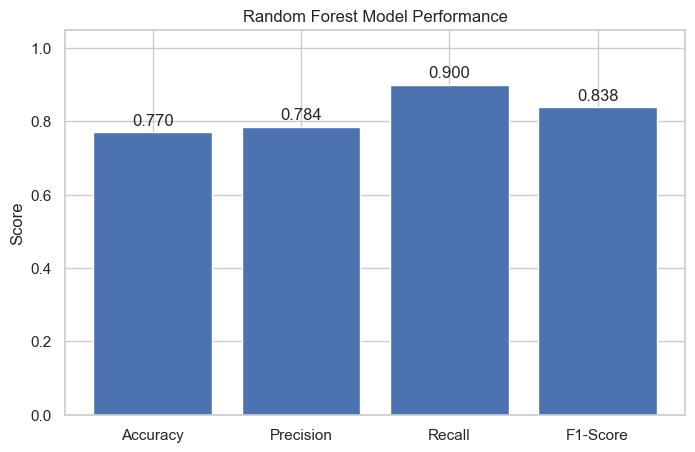

In [16]:
# Visualize model performance
metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
}

plt.figure(figsize=(8, 5))

plt.bar(metrics.keys(), metrics.values())

plt.title("Random Forest Model Performance")
plt.ylabel("Score")
plt.ylim(0, 1.05)

for i, value in enumerate(metrics.values()):
    plt.text(i, value + 0.02, f"{value:.3f}", ha="center")

plt.show()

Feature Importance Ranking:


,Feature,Importance
6,cibil_score,0.386767
4,loan_amount,0.091406
7,residential_assets_value,0.088026
8,commercial_assets_value,0.086115
10,bank_asset_value,0.086115
9,luxury_assets_value,0.082510
3,income_annum,0.082213
0,no_of_dependents,0.038241
5,loan_term,0.034426
2,self_employed,0.012400


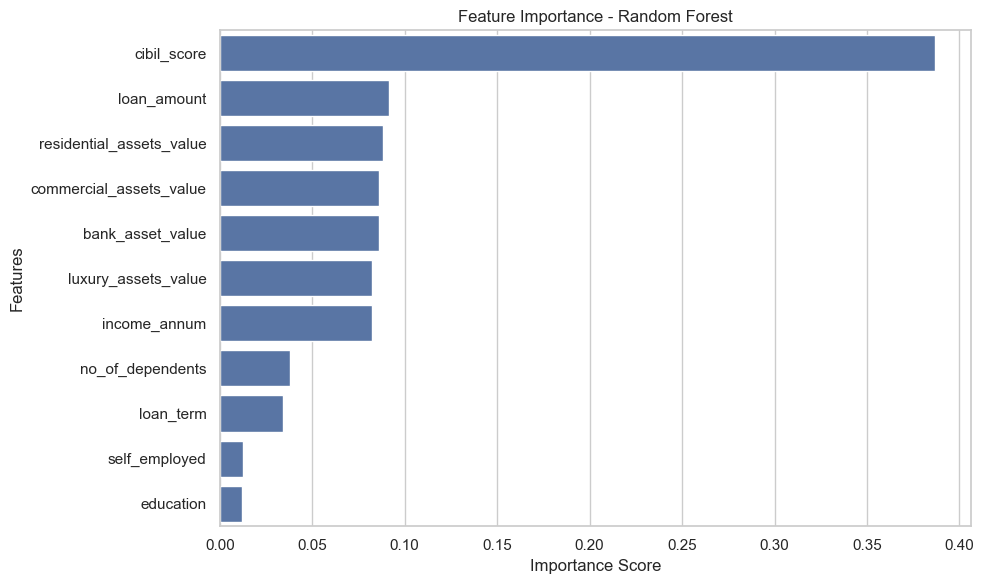

Top 5 Features Influencing Loan Prediction:



,Feature,Importance
6,cibil_score,0.386767
4,loan_amount,0.091406
7,residential_assets_value,0.088026
8,commercial_assets_value,0.086115
10,bank_asset_value,0.086115


In [17]:
# Feature Importance Analysis

# Extract feature importance from Random Forest
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance Ranking:")
display(importance)

#Visualize feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

print("Top 5 Features Influencing Loan Prediction:\n")

display(importance.head(5))

In [18]:
# saving the model
import joblib
# Save trained Random Forest model
joblib.dump(rf_model, "loan_approval_model.pkl")

print("Random Forest Model Saved Successfully!")

Random Forest Model Saved Successfully!


In [19]:
# Load the saved model
loaded_model = joblib.load("loan_approval_model.pkl")

print("Saved Model Loaded Successfully!")

Saved Model Loaded Successfully!


In [23]:
# Interactive Loan Approval Prediction
print("===== NEW LOAN APPLICATION =====")

# Collect applicant details
dependents = int(input("Number of Dependents: "))

education = input(
    "Education (Graduate/Not Graduate): "
).strip().title()

self_employed = input(
    "Self Employed (Yes/No): "
).strip().title()

income = float(input("Annual Income (₹): "))
loan_amount = float(input("Loan Amount (₹): "))
loan_term = float(input("Loan Term (Months): "))
cibil_score = float(input("CIBIL Score: "))

residential = float(input("Residential Assets Value (₹): "))
commercial = float(input("Commercial Assets Value (₹): "))
luxury = float(input("Luxury Assets Value (₹): "))
bank = float(input("Bank Asset Value (₹): "))

===== NEW LOAN APPLICATION =====


Number of Dependents:  2
Education (Graduate/Not Graduate):  Graduate
Self Employed (Yes/No):  Yes
Annual Income (₹):  1000000
Loan Amount (₹):  5000000
Loan Term (Months):  120
CIBIL Score:  799
Residential Assets Value (₹):  5600000
Commercial Assets Value (₹):  5600000
Luxury Assets Value (₹):  120000
Bank Asset Value (₹):  34


In [24]:
# Convert education
if education == "Graduate":
    education = 1
elif education == "Not Graduate":
    education = 0
else:
    raise ValueError("Invalid education input!")

# Convert self employment
if self_employed == "Yes":
    self_employed = 1
elif self_employed == "No":
    self_employed = 0
else:
    raise ValueError("Invalid employment input!")

In [25]:
# Create applicant DataFrame
new_applicant = pd.DataFrame([{
    "no_of_dependents": dependents,
    "education": education,
    "self_employed": self_employed,
    "income_annum": income,
    "loan_amount": loan_amount,
    "loan_term": loan_term,
    "cibil_score": cibil_score,
    "residential_assets_value": residential,
    "commercial_assets_value": commercial,
    "luxury_assets_value": luxury,
    "bank_asset_value": bank
}])

# Match the original training feature order
new_applicant = new_applicant[X.columns]

print("Applicant Information:")
display(new_applicant)

Applicant Information:


,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
0,2,1,1,1000000.0,5000000.0,120.0,799.0,5600000.0,5600000.0,120000.0,34.0


In [26]:
# Make prediction using saved model
prediction = loaded_model.predict(new_applicant)[0]

print("\n===== LOAN PREDICTION RESULT =====")

if prediction == 1:
    print("LOAN STATUS: APPROVED")
else:
    print("LOAN STATUS: REJECTED")

print("\nPrediction Completed!")


===== LOAN PREDICTION RESULT =====
LOAN STATUS: APPROVED

Prediction Completed!
